In [ ]:
# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
import datetime

# ---------------------------------------------------------
# FUNCTION 1: Data Fetching (Uses USGS API)
# ---------------------------------------------------------
def fetch_usgs_data(days_back=30, min_mag=2.5):
    """Fetches earthquake data from USGS API and returns a Pandas DataFrame."""
    end_time = datetime.datetime.now()
    start_time = end_time - datetime.timedelta(days=days_back)

    # Format dates for API
    start_str = start_time.strftime("%Y-%m-%d")
    end_str = end_time.strftime("%Y-%m-%d")

    # USGS API URL for CSV format
    url = f"https://earthquake.usgs.gov/fdsnws/event/1/query?format=csv&starttime={start_str}&endtime={end_str}&minmagnitude={min_mag}"

    print(f"Fetching data from {start_str} to {end_str}...")
    df = pd.read_csv(url)
    return df

# ---------------------------------------------------------
# FUNCTION 2: Magnitude Classification (Uses if/elif/else)
# ---------------------------------------------------------
def classify_magnitude(mag):
    """Assigns an earthquake to a magnitude category."""
    if pd.isna(mag):
        return "Unknown"
    elif mag < 3.0:
        return "Micro"
    elif 3.0 <= mag < 4.0:
        return "Minor"
    elif 4.0 <= mag < 5.0:
        return "Light"
    elif 5.0 <= mag < 6.0:
        return "Moderate"
    elif 6.0 <= mag < 7.0:
        return "Strong"
    else:
        return "Major/Great"

# ---------------------------------------------------------
# FUNCTION 3: Depth Classification (Uses if/elif/else)
# ---------------------------------------------------------
def classify_depth(depth):
    """Classifies depth as shallow, intermediate, or deep."""
    if pd.isna(depth):
        return "Unknown"
    elif depth < 70:
        return "Shallow"
    elif 70 <= depth <= 300:
        return "Intermediate"
    else:
        return "Deep"

# ==========================================
# MAIN EXECUTION & ANALYSIS
# ==========================================

# A. Data Loading and Inspection
eq_df = fetch_usgs_data(days_back=30, min_mag=2.5)
print("\n--- Data Inspection ---")
print(f"Total records found: {len(eq_df)}")
print("Missing values in key columns:")
print(eq_df[['time', 'latitude', 'longitude', 'depth', 'mag', 'place']].isna().sum())

# B. Basic Statistics
total_quakes = len(eq_df)
avg_mag = eq_df['mag'].mean()
max_mag = eq_df['mag'].max()
min_mag = eq_df['mag'].min()
avg_depth = eq_df['depth'].mean()
max_depth = eq_df['depth'].max()
min_depth = eq_df['depth'].min()

print("\n--- Basic Statistics ---")
print(f"Total Earthquakes: {total_quakes}")
print(f"Magnitude: Avg = {avg_mag:.2f}, Min = {min_mag}, Max = {max_mag}")
print(f"Depth (km): Avg = {avg_depth:.2f}, Min = {min_depth}, Max = {max_depth}")

# C & D. Apply Classifications using a loop (satisfying the for-loop requirement)
mag_categories = []
depth_categories = []

for index, row in eq_df.iterrows():
    mag_categories.append(classify_magnitude(row['mag']))
    depth_categories.append(classify_depth(row['depth']))

eq_df['Mag_Class'] = mag_categories
eq_df['Depth_Class'] = depth_categories

# E. Counting with conditions
print("\n--- Event Counts by Category ---")
print("\nBy Magnitude:")
print(eq_df['Mag_Class'].value_counts())
print("\nBy Depth:")
print(eq_df['Depth_Class'].value_counts())

# F. Engineering Event Filter (mag >= 5 and depth < 50 km)
# Useful because shallow, high-magnitude events cause the most surface acceleration/structural damage
eng_filter = eq_df[(eq_df['mag'] >= 5.0) & (eq_df['depth'] < 50)]
print(f"\n--- Engineering Filter ---")
print(f"Found {len(eng_filter)} critical events (Mag >= 5.0 and Depth < 50km).")

# G. Extreme Events
largest_eq = eq_df.loc[eq_df['mag'].idxmax()]
deepest_eq = eq_df.loc[eq_df['depth'].idxmax()]

print("\n--- Extreme Events ---")
print(f"Largest Earthquake: Mag {largest_eq['mag']} at {largest_eq['place']} on {largest_eq['time']}")
print(f"Deepest Earthquake: {deepest_eq['depth']} km at {deepest_eq['place']} on {deepest_eq['time']}")

Fetching data from 2026-09-28 to 2026-10-28...

--- Data Inspection ---
Total records found: 1957
Missing values in key columns:
time         0
latitude     0
longitude    0
depth        0
mag          0
place        0
dtype: int64

--- Basic Statistics ---
Total Earthquakes: 1957
Magnitude: Avg = 3.91, Min = 2.5, Max = 7.7
Depth (km): Avg = 54.20, Min = -3.19, Max = 642.624

--- Event Counts by Category ---

By Magnitude:
Mag_Class
Light          948
Micro          525
Minor          286
Moderate       181
Strong          15
Major/Great      2
Name: count, dtype: int64

By Depth:
Depth_Class
Shallow         1545
Intermediate     346
Deep              66
Name: count, dtype: int64

--- Engineering Filter ---
Found 165 critical events (Mag >= 5.0 and Depth < 50km).

--- Extreme Events ---
Largest Earthquake: Mag 7.7 at 12 km WSW of Pitaloza Arriba, Panama on 2026-10-09T17:56:06.036Z
Deepest Earthquake: 642.624 km at 101 km E of Levuka, Fiji on 2026-10-09T08:27:10.319Z


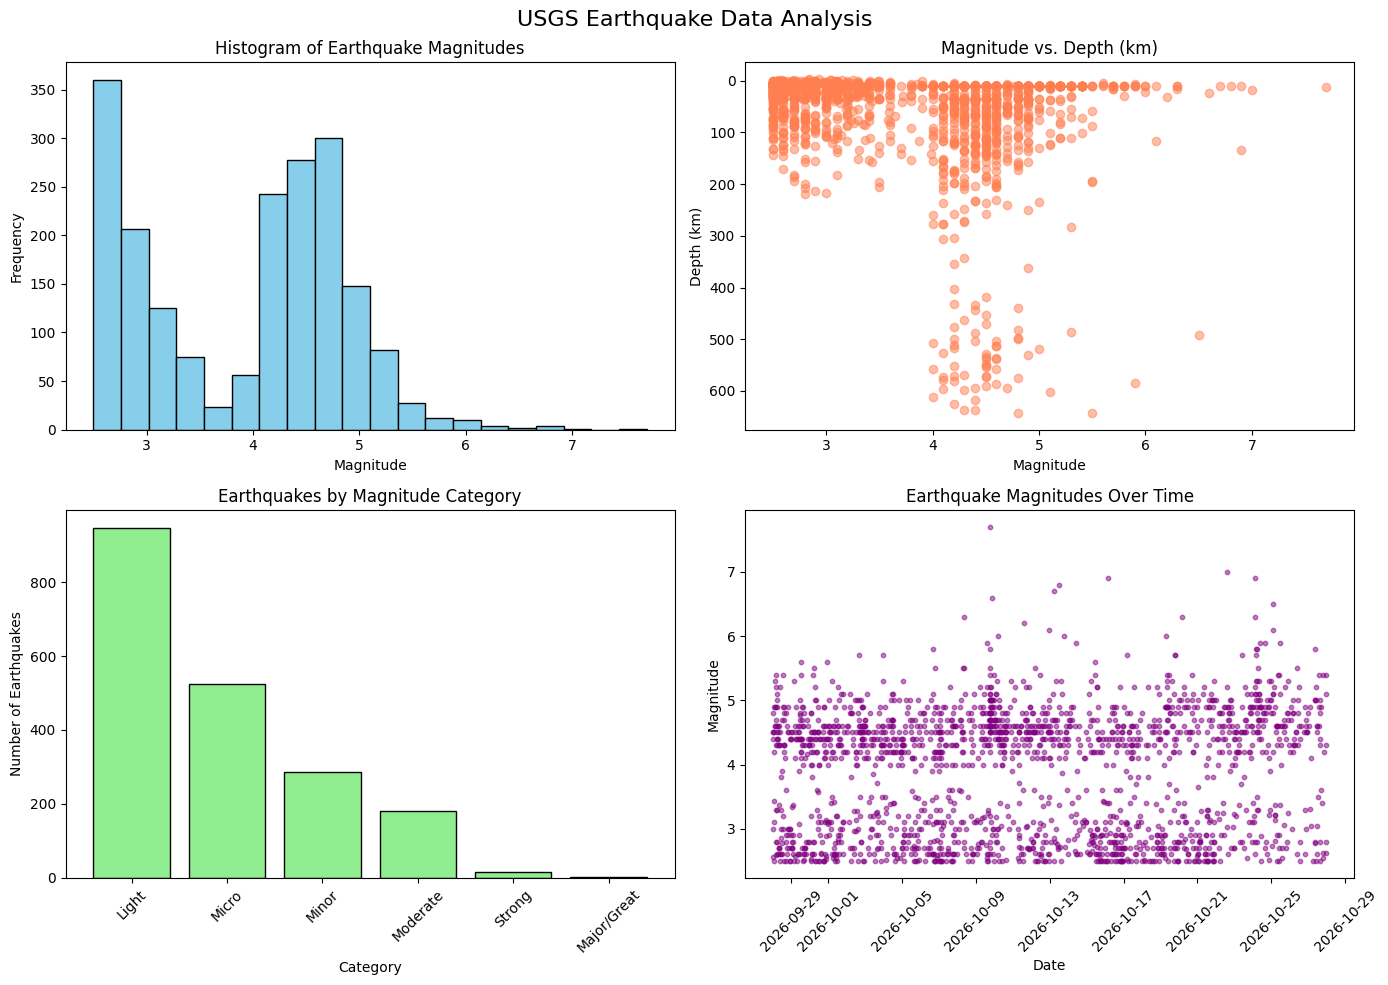

In [ ]:
# Set up a 2x2 grid for subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("USGS Earthquake Data Analysis", fontsize=16)

# 1. Histogram of earthquake magnitudes
axes[0, 0].hist(eq_df['mag'].dropna(), bins=20, color='skyblue', edgecolor='black')
axes[0, 0].set_title("Histogram of Earthquake Magnitudes")
axes[0, 0].set_xlabel("Magnitude")
axes[0, 0].set_ylabel("Frequency")

# 2. Scatter plot of magnitude versus depth
axes[0, 1].scatter(eq_df['mag'], eq_df['depth'], alpha=0.5, color='coral')
axes[0, 1].invert_yaxis() # Depth goes down
axes[0, 1].set_title("Magnitude vs. Depth (km)")
axes[0, 1].set_xlabel("Magnitude")
axes[0, 1].set_ylabel("Depth (km)")

# 3. Bar chart of magnitude categories
mag_counts = eq_df['Mag_Class'].value_counts()
axes[1, 0].bar(mag_counts.index, mag_counts.values, color='lightgreen', edgecolor='black')
axes[1, 0].set_title("Earthquakes by Magnitude Category")
axes[1, 0].set_xlabel("Category")
axes[1, 0].set_ylabel("Number of Earthquakes")
axes[1, 0].tick_params(axis='x', rotation=45)

# 4. Additional Plot: Earthquakes over time
# Convert time to datetime for plotting
eq_df['time_dt'] = pd.to_datetime(eq_df['time'])
axes[1, 1].scatter(eq_df['time_dt'], eq_df['mag'], alpha=0.5, color='purple', s=10)
axes[1, 1].set_title("Earthquake Magnitudes Over Time")
axes[1, 1].set_xlabel("Date")
axes[1, 1].set_ylabel("Magnitude")
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()